In [ ]:
!pip install kaggle

In [ ]:
# configuring the path of Kaggle.json file
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!pip install -q kaggle

Importing Fruit Ripeness Dataset

In [ ]:
!kaggle datasets download -d sumn2u/riped-and-unriped-tomato-dataset

Dataset URL: https://www.kaggle.com/datasets/sumn2u/riped-and-unriped-tomato-dataset
License(s): CC-BY-SA-4.0
riped-and-unriped-tomato-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
# Extracting the compressed Dataset
from zipfile import ZipFile
dataset = '/content/riped-and-unriped-tomato-dataset.zip'

with ZipFile(dataset, 'r') as zip:
    zip.extractall()
    print('The dataset is extracted')

The dataset is extracted


In [ ]:
!ls

 kaggle.json			        sample_data
'Riped and Unriped Tomato Dataset'      tomato_ripeness_model.h5
 riped-and-unriped-tomato-dataset.zip


**Importing the Dependencies**

In [ ]:
import os
import numpy as np
from PIL import Image

# Directory where images are stored
image_dir = '/content/Riped and Unriped Tomato Dataset/Images/'

# Get list of image files (JPEG only)
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.jpeg')])

# Data and labels
data = []
labels = []

# Loop through each image
for img_file in image_files:
    img_path = os.path.join(image_dir, img_file)

    # Load and resize image to 128x128
    image = Image.open(img_path).convert('RGB').resize((128, 128))
    data.append(np.array(image))

    # Label based on filename
    if "riped" in img_file.lower():
        labels.append(1)  # Ripe
    else:
        labels.append(0)  # Not ripe

# Convert to NumPy arrays
X = np.array(data)
Y = np.array(labels)

# Normalize pixel values (0–1)
X = X / 255.0

# Print dataset shapes
print("Data shape:", X.shape)     # (num_samples, 128, 128, 3)
print("Labels shape:", Y.shape)   # (num_samples,)
print("Class distribution:", np.unique(Y, return_counts=True))


Data shape: (177, 128, 128, 3)
Labels shape: (177,)
Class distribution: (array([1]), array([177]))


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Define the model
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Callbacks to detect overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath='best_model.h5',
    save_best_only=True,
    monitor='val_loss',
    mode='min',
    verbose=1
)

# Train the model
history = model.fit(
    X_train, Y_train,
    validation_split=0.1,
    epochs=25,
    callbacks=[early_stop, model_checkpoint]
)

# Print the model summary
model.summary()


Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 1.0000 - loss: 0.2774
Epoch 1: val_loss improved from inf to 0.00000, saving model to best_model.h5


4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 516ms/step - accuracy: 1.0000 - loss: 0.2490 - val_accuracy: 1.0000 - val_loss: 7.7806e-10
Epoch 2/25
1/4 ━━━━━━━━━━━━━━━━━━━━ 7s 3s/step - accuracy: 1.0000 - loss: 6.5696e-09
Epoch 2: val_loss improved from 0.00000 to 0.00000, saving model to best_model.h5


4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 1.0000 - loss: 3.0856e-09 - val_accuracy: 1.0000 - val_loss: 1.0163e-14
Epoch 3/25
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 4.7093e-14
Epoch 3: val_loss improved from 0.00000 to 0.00000, saving model to best_model.h5


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 1.0000 - loss: 1.1697e-13 - val_accuracy: 1.0000 - val_loss: 3.4447e-18
Epoch 4/25
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 1.0000 - loss: 3.2917e-15
Epoch 4: val_loss improved from 0.00000 to 0.00000, saving model to best_model.h5


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 1.0000 - loss: 5.7898e-15 - val_accuracy: 1.0000 - val_loss: 1.0838e-20
Epoch 5/25
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 1.0000 - loss: 9.7032e-22
Epoch 5: val_loss improved from 0.00000 to 0.00000, saving model to best_model.h5


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,545,253 (21.15 MB)

 Trainable params: 1,848,417 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,696,836 (14.10 MB)

In [ ]:
from sklearn.metrics import classification_report

# Predictions
y_pred = model.predict(X_test)
y_pred_classes = (y_pred >= 0.5).astype(int)

print(classification_report(Y_test, y_pred_classes, target_names=['Unripe', 'Ripe']))


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 416ms/step


ValueError: Number of classes, 1, does not match size of target_names, 2. Try specifying the labels parameter

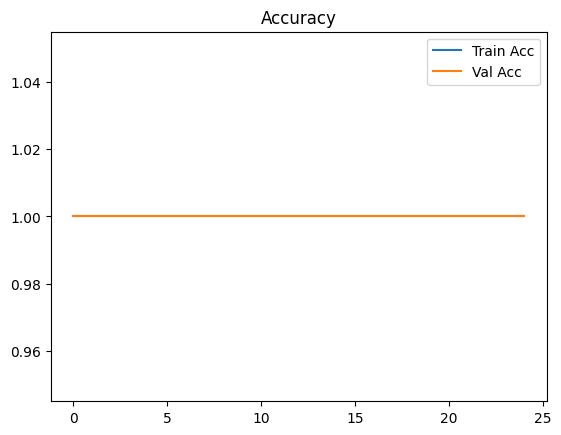

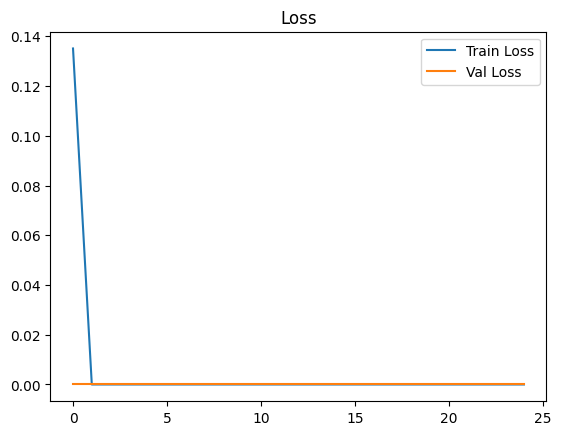

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss")
plt.show()


In [ ]:
model.save("tomato_ripeness_model.h5")
from google.colab import files
files.download("tomato_ripeness_model.h5")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

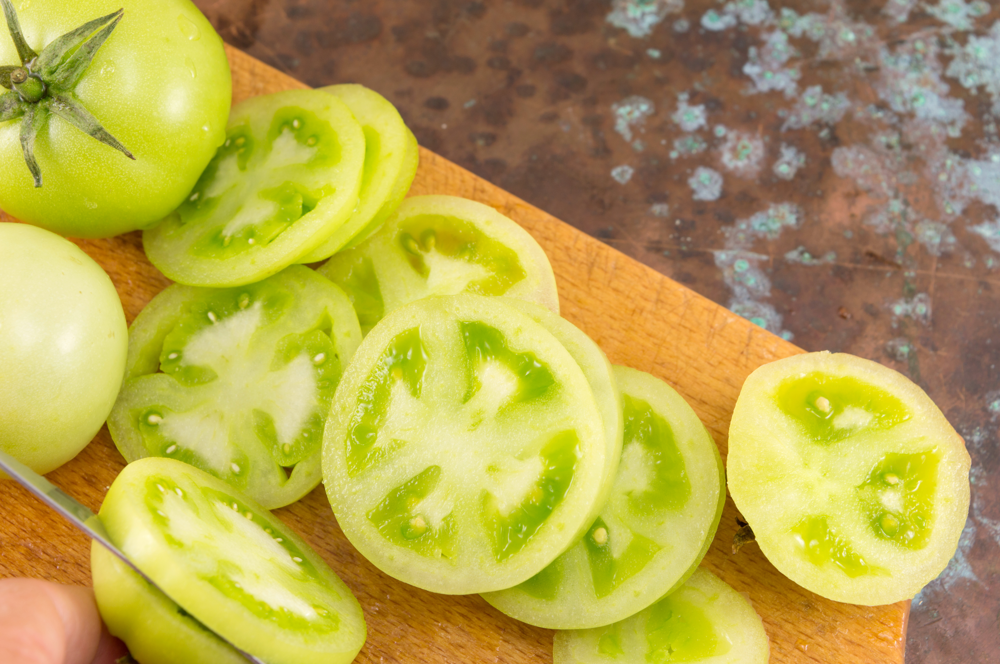

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step
Prediction: RIPE (Confidence: 1.0000)


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Hardcoded image path
path = "/content/Riped and Unriped Tomato Dataset/Images/riped_tomato_7.jpeg"

# Load and display the image
img = cv2.imread(path)
if img is None:
    print("Image not found at the specified path.")
else:
    cv2_imshow(img)

    # Preprocess the image
    resized = cv2.resize(img, (128, 128))
    normalized = resized / 255.0
    reshaped = normalized.reshape(1, 128, 128, 3)

    # Predict ripeness
    pred = model.predict(reshaped)[0][0]
    label = "RIPE" if pred >= 0.5 else "NOT RIPE"
    print(f"Prediction: {label} (Confidence: {pred:.4f})")
